##         Candlestick Pattern Recognition and Trend Analysis with a Multiclassification model




DataSet

For this model, the repository from Roboflow was used. This dataset contains over 9800 images, split up into test and train files. Note that you need an API key hence an account to implement a similar pytorch model yourself.

Goal and Learning Outcome

This project aims to develop a deep learning model that can accurately identify candlestick patterns from stock chart images. By recognizing these patterns, the model will provide actionable insights into market trends, helping evaluate whether the stock exhibits bullish, bearish, or neutral behavior. The system combines image-based pattern classification with domain-specific knowledge of candlestick signals, enabling both automated pattern recognition and trend evaluation for informed trading decisions.

In [ ]:
import torch
from torch import nn

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device, torch.__version__

('cpu', '2.8.0+cu126')

Import the data from roboflow

In [ ]:
import os
# Download the dataset using the code below with your secret private API key.
!pip install roboflow
from pathlib import Path
from roboflow import Roboflow

rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
project = rf.workspace("ranyas-workspace").project("candlestick-pattern-recognition")
version = project.version(2)
dataset = version.download("yolov7")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 66.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.2/4.2 MB 102.4 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.12.0.88
    Uninstalling opencv-python-headless-4.12.0.88:
      Successfully uninstalled opencv-python-headless-4.12.0.88
  Attempting uninstall: idna
    Found existing installation: idna 3.11
    Uninstalling idna-3.11:
      Successfully uninstalled idna-3.11
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Candlestick-Pattern-recognition--2 in yolov7pytorch:: 100%|██████████| 19726/19726 [00:04<00:00, 4159.26it/s]


Organise the Data into clear Train, Test folders.

In [ ]:
# However, the files aren't formatted the way we want them to be. Hence, we use the code below to have a clear strcuture. After that, we can delete the original folder as it won't be of any use and is just a waste of space.


import os
import yaml
import shutil
import zipfile
from pathlib import Path
from sklearn.model_selection import train_test_split

# --- 1. Paths ---
extract_path = Path("/content/Candlestick-Pattern-recognition--2") # Use the extracted directory
base_path = Path("/content/data") # The target base path for the reorganized data
final_path = base_path


# --- 2. Load data.yaml ---
yaml_path = list(extract_path.rglob("data.yaml"))[0]
with open(yaml_path, "r") as f:
    data_cfg = yaml.safe_load(f)

class_names = data_cfg["names"]
print(" Loaded class names:", class_names)

# --- 3. Create target folders ---
for split in ["train", "test"]:
    for cls in class_names:
        os.makedirs(final_path / split / cls, exist_ok=True)

# --- 4. Gather all labeled images ---
image_label_pairs = []
for img_path in extract_path.rglob("train/images/*.jpg"): # Look for images within the 'train' directory
    label_path = str(img_path).replace("images", "labels").replace(".jpg", ".txt")
    if os.path.exists(label_path):
        with open(label_path) as f:
            label_line = f.readline().strip()
            if label_line: # Check if the line is not empty
                label_idx = int(label_line.split()[0])  # first number = class index
                image_label_pairs.append((img_path, class_names[label_idx]))

# Also gather test images separately as they are already in test folder
for img_path in extract_path.rglob("test/images/*.jpg"):
    label_path = str(img_path).replace("images", "labels").replace(".jpg", ".txt")
    if os.path.exists(label_path):
        with open(label_path) as f:
            label_line = f.readline().strip()
            if label_line: # Check if the line is not empty
                label_idx = int(label_line.split()[0])  # first number = class index
                image_label_pairs.append((img_path, class_names[label_idx]))

print(f" Found {len(image_label_pairs)} labeled images.")

# --- 5. Split dataset (80% train, 20% test) ---
# The data is already split into train and test in the downloaded dataset structure.
# Instead of splitting, we will directly use the train and test folders from the extracted data.

train_image_label_pairs = []
for img_path in extract_path.rglob("train/images/*.jpg"):
    label_path = str(img_path).replace("images", "labels").replace(".jpg", ".txt")
    if os.path.exists(label_path):
        with open(label_path) as f:
            label_line = f.readline().strip()
            if label_line:
                label_idx = int(label_line.split()[0])
                train_image_label_pairs.append((img_path, class_names[label_idx]))

test_image_label_pairs = []
for img_path in extract_path.rglob("test/images/*.jpg"):
    label_path = str(img_path).replace("images", "labels").replace(".jpg", ".txt")
    if os.path.exists(label_path):
        with open(label_path) as f:
            label_line = f.readline().strip()
            if label_line:
                label_idx = int(label_line.split()[0])
                test_image_label_pairs.append((img_path, class_names[label_idx]))


splits = {"train": train_image_label_pairs, "test": test_image_label_pairs}

# --- 6. Move images to folders ---
for split_name, data in splits.items():
    for img_path, cls_name in data:
        dest = final_path / split_name / cls_name / img_path.name
        # Create parent directories if they don't exist
        os.makedirs(final_path / split_name / cls_name, exist_ok=True)
        shutil.copy(img_path, dest)

print(" Dataset reorganized successfully into train/test folders!")


✅ Loaded class names: ['Advance Block', 'Dragonfly Doji', 'Evening Doji Star', 'Evening Star', 'Gravestone Doji', 'Hammer', 'Hanging Man', 'Hikkake Pattern', 'Identical Three Crows', 'Ladder Bottom', 'Marubozu', 'Morning Doji Star', 'Morning Star', 'Rising-Falling Three Methods', 'Spinning Top', 'Stick Sandwich', 'Tasuki Gap', 'Three Advancing White Soldiers', 'Three Black Crows', 'Three Inside Up-Down', 'Three Line Strike', 'Three Outside Up-Down', 'Tristar Pattern', 'Unique 3 River', 'Up-Down Gap Side-by-side White Lines', 'Upside-Downside Gap Three Methods']
✅ Found 7883 labeled images.
 Dataset reorganized successfully into train/test folders!


In [ ]:
import shutil
folder_path = "/content/Candlestick-Pattern-recognition--2"
# Recursively delete folder and all contents
shutil.rmtree(folder_path)
print("Folder deleted successfully!")

Folder deleted successfully!


## 2. Becoming one with the Data. Converting the images into tensors for ML

In [ ]:
import os
def walk_through_dir(dir_path):
  """ Walks through dir_path returning its conetens."""
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f" There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

walk_through_dir("/content/data")

 There are 2 directories and 0 images in '/content/data'.
 There are 26 directories and 0 images in '/content/data/test'.
 There are 0 directories and 297 images in '/content/data/test/Spinning Top'.
 There are 0 directories and 0 images in '/content/data/test/Ladder Bottom'.
 There are 0 directories and 0 images in '/content/data/test/Identical Three Crows'.
 There are 0 directories and 1 images in '/content/data/test/Unique 3 River'.
 There are 0 directories and 0 images in '/content/data/test/Three Black Crows'.
 There are 0 directories and 23 images in '/content/data/test/Advance Block'.
 There are 0 directories and 1 images in '/content/data/test/Three Advancing White Soldiers'.
 There are 0 directories and 6 images in '/content/data/test/Evening Star'.
 There are 0 directories and 29 images in '/content/data/test/Hanging Man'.
 There are 0 directories and 12 images in '/content/data/test/Upside-Downside Gap Three Methods'.
 There are 0 directories and 9 images in '/content/data/t

This shows that our dataset is very imbalanced. While few have over a 1000 images, few have below 10. This creates bias when training our models. To fix that, let's have approxiamtley 150 images per group and include a few smaller ones with around 70 images. Let's write some code to do that for us!

In [ ]:
import os
import shutil
import random

src_dir = '/content/data'
dst_dir = '/content/data_model'

# Classes to always keep, even if <150
small_classes = [
    'Upside-Downside Gap Three Methods',
    'Morning Star',
    'Evening Star',
    'Three Line Strike'
]

# Create train/test folders
os.makedirs(os.path.join(dst_dir, 'train'), exist_ok=True)
os.makedirs(os.path.join(dst_dir, 'test'), exist_ok=True)

def copy_images(src_folder, dst_folder, max_images=None):
    os.makedirs(dst_folder, exist_ok=True)
    images = [f for f in os.listdir(src_folder) if os.path.isfile(os.path.join(src_folder, f))]
    if max_images and len(images) > max_images:
        images = random.sample(images, max_images)
    for f in images:
        shutil.copy(os.path.join(src_folder, f), os.path.join(dst_folder, f))
    return len(images)

def process_class(class_name):
    train_src = os.path.join(src_dir, 'train', class_name)
    test_src = os.path.join(src_dir, 'test', class_name)
    train_dst = os.path.join(dst_dir, 'train', class_name)
    test_dst = os.path.join(dst_dir, 'test', class_name)

    if not os.path.isdir(train_src):
        return 0, 0  # skip if no train folder

    # Count train images
    num_train_images = len([f for f in os.listdir(train_src) if os.path.isfile(os.path.join(train_src, f))])

    # Decide if this class should be included
    if num_train_images >= 150 or class_name in small_classes:
        # For large classes, randomly pick 150 images
        if num_train_images >= 150 and class_name not in small_classes:
            copied_train = copy_images(train_src, train_dst, max_images=150)
        else:
            copied_train = copy_images(train_src, train_dst)  # keep all small classes

        # Copy test images fully if exist
        copied_test = 0
        if os.path.isdir(test_src):
            copied_test = copy_images(test_src, test_dst)

        return copied_train, copied_test
    else:
        return 0, 0  # skip very small classes

# Loop over all classes in train folder
for cls in os.listdir(os.path.join(src_dir, 'train')):
    cls_path = os.path.join(src_dir, 'train', cls)
    if os.path.isdir(cls_path):
        train_count, test_count = process_class(cls)
        if train_count > 0:
            print(f"{cls}: train={train_count}, test={test_count} included")
        else:
            print(f"{cls}: skipped (too small)")

print("data_model folder created with proper sampling and small classes retained.")

Spinning Top: train=150, test=297 included
Ladder Bottom: skipped (too small)
Identical Three Crows: skipped (too small)
Unique 3 River: skipped (too small)
Three Black Crows: skipped (too small)
Advance Block: train=150, test=23 included
Three Advancing White Soldiers: skipped (too small)
Evening Star: train=61, test=6 included
Hanging Man: train=150, test=29 included
Upside-Downside Gap Three Methods: train=68, test=12 included
Morning Star: train=51, test=9 included
Hikkake Pattern: train=150, test=234 included
Three Outside Up-Down: train=150, test=76 included
Up-Down Gap Side-by-side White Lines: skipped (too small)
Tristar Pattern: skipped (too small)
Morning Doji Star: skipped (too small)
Dragonfly Doji: train=150, test=53 included
Three Line Strike: train=52, test=10 included
Marubozu: train=150, test=102 included
Tasuki Gap: skipped (too small)
Rising-Falling Three Methods: skipped (too small)
Gravestone Doji: train=150, test=74 included
Hammer: train=150, test=41 included
Eve

In [ ]:
import os
import shutil
import random
from pathlib import Path

test_dir = Path("/content/data_model/test")  # current test folder

# Target test counts (you can adjust as needed)
target_test_counts = {
    "Spinning Top": 50,
    "Advance Block": 10,
    "Evening Star": 10,
    "Hanging Man": 20,
    "Upside-Downside Gap Three Methods": 10,
    "Morning Star": 10,
    "Hikkake Pattern": 50,
    "Three Outside Up-Down": 30,
    "Dragonfly Doji": 20,
    "Three Line Strike": 10,
    "Marubozu": 50,
    "Gravestone Doji": 30,
    "Hammer": 20,
    "Three Inside Up-Down": 10
}

for cls_name, target_count in target_test_counts.items():
    cls_path = test_dir / cls_name
    if not cls_path.exists():
        continue

    images = [f for f in os.listdir(cls_path) if os.path.isfile(cls_path / f)]
    random.shuffle(images)

    # Keep only target_count images
    keep_images = images[:target_count]
    remove_images = images[target_count:]

    for img in remove_images:
        os.remove(cls_path / img)

    print(f"{cls_name}: test set reduced to {len(keep_images)} images.")

print("✅ Test sets reduced successfully.")

Spinning Top: test set reduced to 50 images.
Advance Block: test set reduced to 10 images.
Evening Star: test set reduced to 6 images.
Hanging Man: test set reduced to 20 images.
Upside-Downside Gap Three Methods: test set reduced to 10 images.
Morning Star: test set reduced to 9 images.
Hikkake Pattern: test set reduced to 50 images.
Three Outside Up-Down: test set reduced to 30 images.
Dragonfly Doji: test set reduced to 20 images.
Three Line Strike: test set reduced to 10 images.
Marubozu: test set reduced to 50 images.
Gravestone Doji: test set reduced to 30 images.
Hammer: test set reduced to 20 images.
Three Inside Up-Down: test set reduced to 10 images.
✅ Test sets reduced successfully.


In [ ]:
import os

def walk_through_dir(dir_path):
  """ Walks through dir_path returning its conetens."""
  for dirpath, dirnames, filenames in os.walk(dir_path):
    print(f" There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

walk_through_dir("/content/data_model")

 There are 2 directories and 0 images in '/content/data_model'.
 There are 14 directories and 0 images in '/content/data_model/test'.
 There are 0 directories and 50 images in '/content/data_model/test/Spinning Top'.
 There are 0 directories and 10 images in '/content/data_model/test/Advance Block'.
 There are 0 directories and 6 images in '/content/data_model/test/Evening Star'.
 There are 0 directories and 20 images in '/content/data_model/test/Hanging Man'.
 There are 0 directories and 10 images in '/content/data_model/test/Upside-Downside Gap Three Methods'.
 There are 0 directories and 9 images in '/content/data_model/test/Morning Star'.
 There are 0 directories and 50 images in '/content/data_model/test/Hikkake Pattern'.
 There are 0 directories and 30 images in '/content/data_model/test/Three Outside Up-Down'.
 There are 0 directories and 20 images in '/content/data_model/test/Dragonfly Doji'.
 There are 0 directories and 10 images in '/content/data_model/test/Three Line Strike'

We now have classes in the format and size that we wished for!

In [ ]:
train_dir = Path("/content/data_model") / "train"
test_dir = Path("/content/data_model") / "test"

train_dir, test_dir

(PosixPath('/content/data_model/train'), PosixPath('/content/data_model/test'))

## 2.1 Visualizing and image

Objective:
1. Get all image paths
2. Pick a random path using Pythons random.choice()
3. Get the image class using `pathlib.Path.parent.stem`
4. Using pythons PIL and working with python images
5. Show image and print metadata.

 Random Image Path: /content/data_model/train/Evening Star/1515_png_jpg.rf.f5581b7d9f87d858eac17d2b03633a2a.jpg
Image Class: Evening Star
Image Size: (640, 640)
 Image height: 640
 Image width: 640


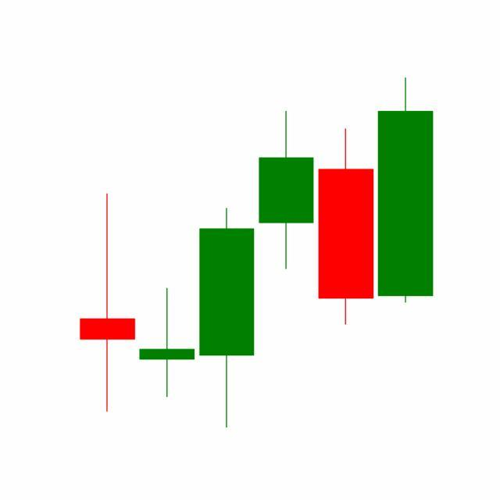

In [ ]:
import random
from PIL import Image
from pathlib import Path

# 1. Get all image paths
image_path_list = list(train_dir.glob("*/*.jpg"))
image_path_list

# 2. Pick a random image path
random_image_path = random.choice(image_path_list)
random_image_path

# 3. Get the image class from the path name (dir name where img is stored)
image_class = random_image_path.parent.stem
image_class

# 4. Open image
img = Image.open(random_image_path)

# 5. Print metadata
print(f" Random Image Path: {random_image_path}")
print(f"Image Class: {image_class}")
print(f"Image Size: {img.size}")
print(f" Image height: {img.height}")
print(f" Image width: {img.width}")
img = img.resize((500, 500)) # Use img.resize() method to resize the image
img

Alternative: Visualizing with Matplotlyb.pylot

(np.float64(-0.5), np.float64(499.5), np.float64(499.5), np.float64(-0.5))

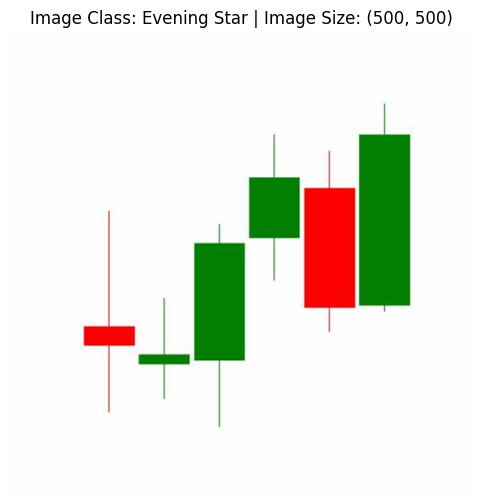

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Turn the image into an array
img_array = np.asarray(img)
img_array.shape

# Plot the image
plt.figure(figsize=(6, 6))
plt.imshow(img_array)
plt.title(f"Image Class: {image_class} | Image Size: {img.size}")
plt.axis("off")

## 3. Transforming Data

Before we can use our data with pytorch:
1. Turn your target data into tensors. In this case, numerical representation of our images.
2. Turn it into a `torch.utils.data.Dataset` and subsequently a `torch.utils.data.DataLoader`, we 'll call these dataset and dataloader.

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

## 3.1 Transforming Data with `torchvision.transforms`

In [ ]:
# Wrte a transform for image
data_transform = transforms.Compose([
    # Resize to 64 x 64
    transforms.Resize((224, 224)),
    # Flip images randomly
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

In [ ]:
data_transform(img), data_transform(img).shape, data_transform(img).dtype

(tensor([[[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          ...,
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961]],
 
         [[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          ...,
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961]],
 
         [[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
          [0.9961, 0.9961, 0.9961,  ...,

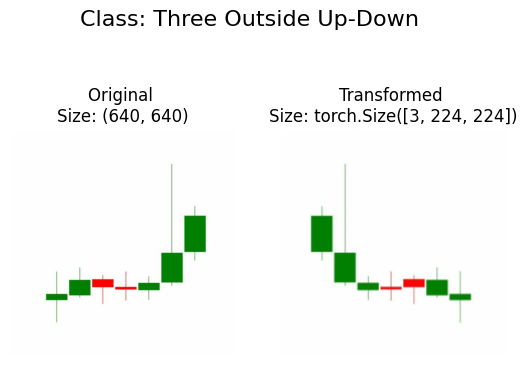

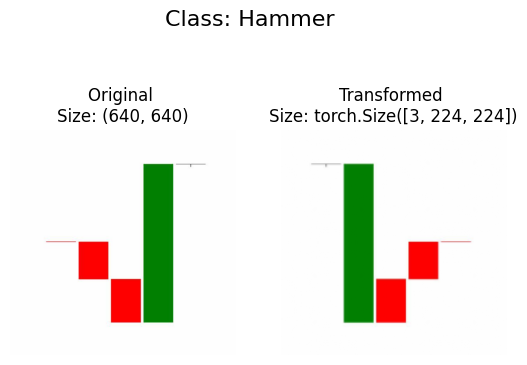

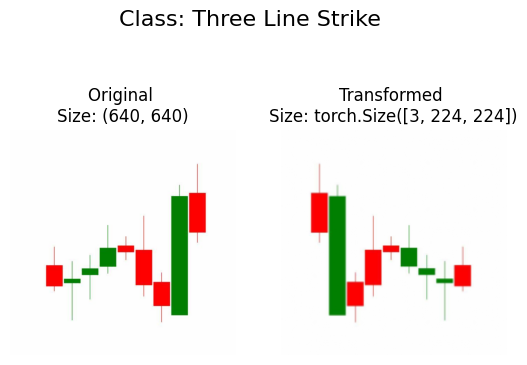

In [ ]:
def plot_transformed_images(image_paths, transform, n=3, seed=None):

    """Plots a transformed image. In other words, the image that the ML model did mathamatical operations on. Let's look at Original vs Transformed version. """

    if seed:
        random.seed(seed)
    random_image_paths = random.sample(image_paths, k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig, ax = plt.subplots(1, 2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original \nSize: {f.size}")
            ax[0].axis("off")

            # Transform and plot image
            transformed_image = transform(f) # will have to fix due to shape
            # PyTorch image tensors are in shape [C, H, W] but Matplotlib expects [H, W, C]
            # so we need to rearrange the dimensions with permute()
            ax[1].imshow(transformed_image.permute(1, 2, 0))
            ax[1].set_title(f"Transformed \nSize: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}", fontsize=16)
plot_transformed_images(image_path_list, data_transform, n=3)

## 4. Option 1: Loading image data using `ImageFolder`


In [ ]:
# Use ImageFolder to create datasets(s)
from torchvision import datasets, transforms
train_data = datasets.ImageFolder(root = train_dir, transform=data_transform, target_transform=None)
test_data = datasets.ImageFolder(root = train_dir, transform=data_transform, target_transform=None)
train_data, test_data

(Dataset ImageFolder
     Number of datapoints: 1732
     Root location: /content/data_model/train
     StandardTransform
 Transform: Compose(
                Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 1732
     Root location: /content/data_model/train
     StandardTransform
 Transform: Compose(
                Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [ ]:
train_dir, test_dir

(PosixPath('/content/data_model/train'), PosixPath('/content/data_model/test'))

In [ ]:
class_names = train_data.classes
class_names

['Advance Block',
 'Dragonfly Doji',
 'Evening Star',
 'Gravestone Doji',
 'Hammer',
 'Hanging Man',
 'Hikkake Pattern',
 'Marubozu',
 'Morning Star',
 'Spinning Top',
 'Three Inside Up-Down',
 'Three Line Strike',
 'Three Outside Up-Down',
 'Upside-Downside Gap Three Methods']

In [ ]:
class_dict = train_data.class_to_idx
class_dict

{'Advance Block': 0,
 'Dragonfly Doji': 1,
 'Evening Star': 2,
 'Gravestone Doji': 3,
 'Hammer': 4,
 'Hanging Man': 5,
 'Hikkake Pattern': 6,
 'Marubozu': 7,
 'Morning Star': 8,
 'Spinning Top': 9,
 'Three Inside Up-Down': 10,
 'Three Line Strike': 11,
 'Three Outside Up-Down': 12,
 'Upside-Downside Gap Three Methods': 13}

In [ ]:
len(test_data), len(train_data)

(1732, 1732)

In [ ]:
train_data.samples[0]

('/content/data_model/train/Advance Block/1076_png_jpg.rf.d90467ea28e4dabe26fb0d55e738aa93.jpg',
 0)

In [ ]:
img, label = train_data[0][0], train_data[0][1]
print(f'Image shape: {img.shape}')
print(f'Image label: {label}')
print(f'Image Datatype: {img.dtype}')
print(f'Image tensor: {img}')
print(f'Label Datatype: {type(label)}')


Image shape: torch.Size([3, 224, 224])
Image label: 0
Image Datatype: torch.float32
Image tensor: tensor([[[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         ...,
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961]],

        [[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         ...,
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961]],

        [[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961,

Original shape: torch.Size([3, 224, 224]) -> [color_channels, height, width]
Shape after permute


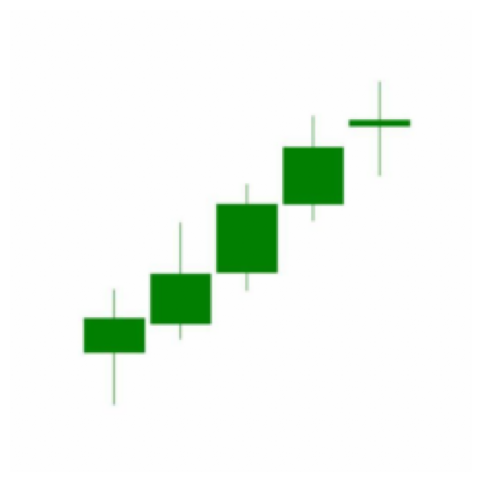

In [ ]:
# Rearrange order of dimensions
img_permute = img.permute(1, 2, 0)
# print out different shapes
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Shape after permute")

# Plot the image
plt.figure(figsize=(6, 6))
plt.axis("off")
plt.imshow(img_permute)

## 4.1 Turn loaded images into `DataLoader` 's

A dataloader is going to help us turn our Dataset's into iterables and we can customise the batch_size so our model can see t he batch_size images at a time.

In [ ]:
# Turn train and test datasets into DataLoaders
from torch.utils.data import DataLoader
BATCH_SIZE = 32
train_dataloader = DataLoader(dataset=train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=1)
test_dataloader = DataLoader(dataset=test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=1)
train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7c6e46920f50>,
 <torch.utils.data.dataloader.DataLoader at 0x7c6e468e4b30>)

In [ ]:
len(train_dataloader), len(test_dataloader)

(55, 55)

In [ ]:
img, label = next(iter(train_dataloader))
# batch size wll be 1, you can change it later if you wish
print(f'Image Shape: {img.shape}')
print(f" Label shape: {label.shape}")

Image Shape: torch.Size([32, 3, 224, 224])
 Label shape: torch.Size([32])


## 5. Option 2:  Loading Image Data with a Custom Dataset
1. Want to be able to load images from file  
2. Want to be able to get class names from the Dataset
3. Want to be able to get classes as dictionary from the Dataset

Pros:
*   Can create a datset out of anything
*   Not limited to Pytorch pre-built Dataset function

Cons:
- More code required => Maybe more error prone



In [ ]:
import os
import pathlib
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple, Dict, List

In [ ]:
train_data.classes, train_data.class_to_idx

(['Advance Block',
  'Dragonfly Doji',
  'Evening Star',
  'Gravestone Doji',
  'Hammer',
  'Hanging Man',
  'Hikkake Pattern',
  'Marubozu',
  'Morning Star',
  'Spinning Top',
  'Three Inside Up-Down',
  'Three Line Strike',
  'Three Outside Up-Down',
  'Upside-Downside Gap Three Methods'],
 {'Advance Block': 0,
  'Dragonfly Doji': 1,
  'Evening Star': 2,
  'Gravestone Doji': 3,
  'Hammer': 4,
  'Hanging Man': 5,
  'Hikkake Pattern': 6,
  'Marubozu': 7,
  'Morning Star': 8,
  'Spinning Top': 9,
  'Three Inside Up-Down': 10,
  'Three Line Strike': 11,
  'Three Outside Up-Down': 12,
  'Upside-Downside Gap Three Methods': 13})

## 5.1 Creating a helper function to get class name

We want to:
1. Get the class name
2. Raise an error if not found
3. Turn the class names into a dict and a list and return


In [ ]:
target_directory = train_dir
print(f'Target directory: {target_directory}')
class_names_found = sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Target directory: /content/data_model/train


['Advance Block',
 'Dragonfly Doji',
 'Evening Star',
 'Gravestone Doji',
 'Hammer',
 'Hanging Man',
 'Hikkake Pattern',
 'Marubozu',
 'Morning Star',
 'Spinning Top',
 'Three Inside Up-Down',
 'Three Line Strike',
 'Three Outside Up-Down',
 'Upside-Downside Gap Three Methods']

In [ ]:
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
    """ Find and return the class folder names in a target dir."""
    # 1. Scanning the dir
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())

    # 2. Raise an err
    if not classes:
      raise FileNotFoundError(f"Couldn't find any classes in {directory}.... Please check file structure")

    # 3. Create a dict of index labels
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
    return classes, class_to_idx

## 5.2 Create a custom Dataset to replicate ImageFolder

To create our own custom dataset, we want to:
1. Subclass torch.utils.data.Dataset
2. Init our subclass with a target directory
3. Create several attributes like paths, transform, classes, class_to_idx.
4. Create a def to load_images()
5. Overwrite the __len()__to return the length of the dataset
6. Overwrite the __getitem()__ method to return a given sample

In [ ]:
# Write a custom dataset class (inherits from torch.utils.data.Dataset)
from torch.utils.data import Dataset

# 1. Subclass torch.utils.data.Dataset
class ImageFolderCustom(Dataset):

    # 2. Initialize with a targ_dir and transform (optional) parameter
    def __init__(self, targ_dir: str, transform=None) -> None:

        # 3. Create class attributes
        # Get all image paths
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg")) # note: you'd have to update this if you've got .png's or .jpeg's
        # Setup transforms
        self.transform = transform
        # Create classes and class_to_idx attributes
        self.classes, self.class_to_idx = find_classes(targ_dir)

    # 4. Make function to load images
    def load_image(self, index: int) -> Image.Image:
        "Opens an image via a path and returns it."
        image_path = self.paths[index]
        return Image.open(image_path)

    # 5. Overwrite the __len__() method (optional but recommended for subclasses of torch.utils.data.Dataset)
    def __len__(self) -> int:
        "Returns the total number of samples."
        return len(self.paths)

    # 6. Overwrite the __getitem__() method (required for subclasses of torch.utils.data.Dataset)
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        "Returns one sample of data, data and label (X, y)."
        img = self.load_image(index)
        class_name  = self.paths[index].parent.name # expects path in data_folder/class_name/image.jpeg
        class_idx = self.class_to_idx[class_name]

        # Transform if necessary
        if self.transform:
            return self.transform(img), class_idx # return data, label (X, y)
        else:
            return img, class_idx # return data, label (X, y)

In [ ]:
from torchvision import transforms
train_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor()
])

# Don't augment test data, only reshape
test_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

In [ ]:

train_data_custom = ImageFolderCustom(targ_dir=train_dir,
                                      transform=train_transforms)
test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                     transform=test_transforms)
train_data_custom, test_data_custom

(<__main__.ImageFolderCustom at 0x7c6e46859e80>,
 <__main__.ImageFolderCustom at 0x7c6e46c70500>)

In [ ]:
len(train_data), len(train_data_custom)

(1732, 1732)

In [ ]:
train_data_custom.classes, train_data_custom.class_to_idx

(['Advance Block',
  'Dragonfly Doji',
  'Evening Star',
  'Gravestone Doji',
  'Hammer',
  'Hanging Man',
  'Hikkake Pattern',
  'Marubozu',
  'Morning Star',
  'Spinning Top',
  'Three Inside Up-Down',
  'Three Line Strike',
  'Three Outside Up-Down',
  'Upside-Downside Gap Three Methods'],
 {'Advance Block': 0,
  'Dragonfly Doji': 1,
  'Evening Star': 2,
  'Gravestone Doji': 3,
  'Hammer': 4,
  'Hanging Man': 5,
  'Hikkake Pattern': 6,
  'Marubozu': 7,
  'Morning Star': 8,
  'Spinning Top': 9,
  'Three Inside Up-Down': 10,
  'Three Line Strike': 11,
  'Three Outside Up-Down': 12,
  'Upside-Downside Gap Three Methods': 13})

In [ ]:
print(train_data_custom.classes == train_data.classes)
print(train_data_custom.class_to_idx == train_data.class_to_idx)

True
True


## 5.3 Create a function to display random images

Let's create a helper function called display_random_images() that helps us visualize images in our Dataset's.

Specifically, it'll:

Take in a Dataset and a number of other parameters such as classes (the names of our target classes), the number of images to display (n) and a random seed.

To prevent the display getting out of hand, we'll cap n at 10 images.
Set the random seed for reproducible plots (if seed is set).

Get a list of random sample indexes (we can use Python's random.sample() for this) to plot.

Setup a matplotlib plot.

Loop through the random sample indexes found in step 4 and plot them with matplotlib.
Make sure the sample images are of shape HWC (height, width, color channels) so we can plot them.

In [ ]:
import matplotlib.pyplot as plt

def display_random_images(dataset: torch.utils.data.dataset.Dataset,
                          classes: List[str] = None,
                          n: int = 10,
                          display_shape: bool = True,
                          seed: int = None):

    # 2. Adjust display if n too high
    if n > 10:
        n = 10
        display_shape = False
        print(f"For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")

    # 3. Set random seed
    if seed:
        random.seed(seed)

    # 4. Get random sample indexes
    random_samples_idx = random.sample(range(len(dataset)), k=n)

    # 5. Setup plot
    plt.figure(figsize=(16, 8))

    # 6. Loop through samples and display random samples
    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]

        # 7. Adjust image tensor shape for plotting: [color_channels, height, width] -> [height, width, color_channels]
        targ_image_adjust = targ_image.permute(1, 2, 0)

        # Plot adjusted samples
        plt.subplot(1, n, i+1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")
        if classes:
            title = f"class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title)

    # Add tight layout to prevent titles from overlapping
    plt.tight_layout()

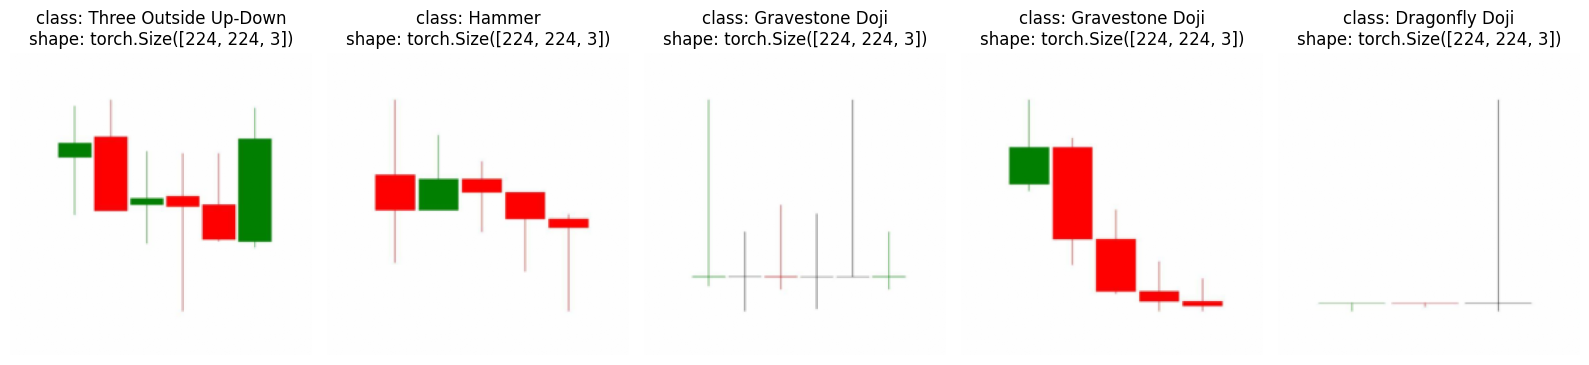

In [ ]:
# Display random images
display_random_images(train_data, n=5, classes = class_names, seed = None)

## 5.4 Turn custom loaded imafes into DataLoader's

In [ ]:
# Turn train and test custom Dataset's into DataLoader's
from torch.utils.data import DataLoader
BATCH_SIZE = 32

train_dataloader_custom = DataLoader(dataset=train_data_custom, # use custom created train Dataset
                                     batch_size= BATCH_SIZE, # how many samples per batch?
                                     num_workers=0, # how many subprocesses to use for data loading? (higher = more)
                                     shuffle=True) # shuffle the data?

test_dataloader_custom = DataLoader(dataset=test_data_custom, # use custom created test Dataset
                                    batch_size=1,
                                    num_workers=0,
                                    shuffle=False) # don't usually need to shuffle testing data

train_dataloader_custom, test_dataloader_custom

(<torch.utils.data.dataloader.DataLoader at 0x7c6e44dae900>,
 <torch.utils.data.dataloader.DataLoader at 0x7c6e46d85790>)

In [ ]:
# Get image and label from custom DataLoader
img_custom, label_custom = next(iter(train_dataloader_custom))

# Batch size will now be 1, try changing the batch_size parameter above and see what happens
print(f"Image shape: {img_custom.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label_custom.shape}")

Image shape: torch.Size([32, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([32])


## 6. Other forms of Data Augmentation
Basically, the process of artificially tweaking or editing our images and using them to train our model. This is supposed to help compensate for the differences in real life. Examples include rotating, shifting, zooming, and much more.

Same data, slight difference in representation, useful for training models versatility by increasing diversity.

In [ ]:
from torchvision import transforms

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31), # how intense
    transforms.ToTensor() # use ToTensor() last to get everything between 0 & 1
])

# Don't need to perform augmentation on the test data
test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


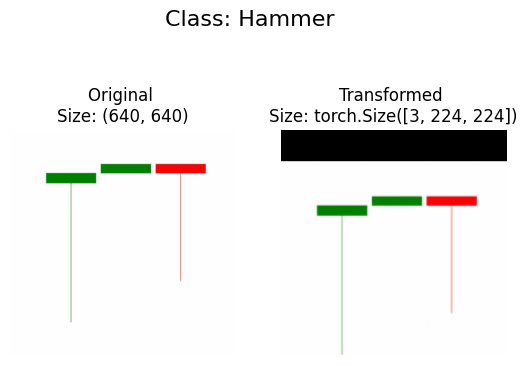

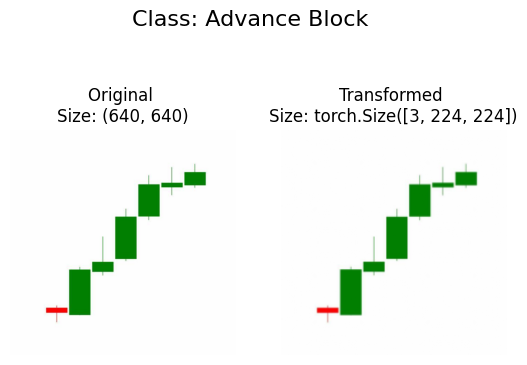

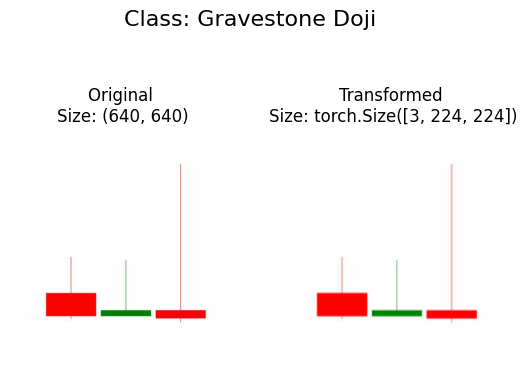

In [ ]:
# Get all image paths
image_path_list = list(train_dir.glob("*/*.jpg"))

# Plot random images
plot_transformed_images(
    image_paths=image_path_list,
    transform=train_transforms,
    n=3,
    seed=None
)

## 7. Model 0: TinyVGG without data augmentation
Let's replicate TinyVGG architecture.


## 7.1 Creating transforms and loading data for model 0

In [ ]:
# Create simple transform
simple_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

In [ ]:
# 1. Import and define variables
from torchvision import datasets
train_data_simple = datasets.ImageFolder(root = train_dir, transform=simple_transform)
test_data_simple = datasets.ImageFolder(root = test_dir, transform=simple_transform)

#  2. Turn the datasets into Dataloaders
import os
from torch.utils.data import DataLoader

# 3. Set up batch size and number of works
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

# Create a test loader
train_dataloader_simple = DataLoader(dataset=train_data_simple, batch_size=BATCH_SIZE , shuffle = True, num_workers=NUM_WORKERS)
test_dataloader_simple = DataLoader(dataset=test_data_simple, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)



## 7.2 Create a TinyVGG model class

In [ ]:
class TinyVGG(nn.Module):
    """
    Model architecture copying TinyVGG from:
    https://poloclub.github.io/cnn-explainer/
    """
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int) -> None:
        super().__init__()
        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3, # how big is the square that's going over the image?
                      stride=1, # default
                      padding=1), # options = "valid" (no padding) or "same" (output has same shape as input) or int for specific number
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,
                         stride=2) # default stride value is same as kernel_size
        )
        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            # Where did this in_features shape come from?
            # It's because each layer of our network compresses and changes the shape of our input data.
            nn.Linear(in_features=hidden_units*16*16,
                      out_features=output_shape)
        )

    def forward(self, x: torch.Tensor):
        x = self.conv_block_1(x)
        # print(x.shape)
        x = self.conv_block_2(x)
        # print(x.shape)
        x = self.classifier(x)
        # print(x.shape)
        return x
        # return self.classifier(self.conv_block_2(self.conv_block_1(x))) # <- leverage the benefits of operator fusion

model_0 = TinyVGG(input_shape=3, # number of color channels (3 for RGB)
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=14, bias=True)
  )
)

## 7.3 Try a forward pass, to test the model

In [ ]:
image_batch , label_batch = next(iter(train_dataloader_simple))
image_batch = image_batch.to(device)
label_batch = label_batch.to(device)
image_batch.shape, label_batch.shape

(torch.Size([32, 3, 64, 64]), torch.Size([32]))

In [ ]:
model_0(image_batch.to(device))

tensor([[ 0.0890,  0.0721,  0.0182, -0.0269, -0.0450,  0.0668, -0.0685,  0.0820,
         -0.0100,  0.0648, -0.0410, -0.0216,  0.0167, -0.0197],
        [ 0.0879,  0.0724,  0.0183, -0.0271, -0.0445,  0.0659, -0.0689,  0.0819,
         -0.0107,  0.0648, -0.0405, -0.0206,  0.0172, -0.0197],
        [ 0.0885,  0.0723,  0.0179, -0.0259, -0.0444,  0.0670, -0.0685,  0.0814,
         -0.0095,  0.0657, -0.0402, -0.0199,  0.0162, -0.0180],
        [ 0.0914,  0.0727,  0.0195, -0.0262, -0.0445,  0.0674, -0.0670,  0.0839,
         -0.0110,  0.0647, -0.0420, -0.0227,  0.0154, -0.0213],
        [ 0.0872,  0.0722,  0.0197, -0.0284, -0.0451,  0.0664, -0.0693,  0.0834,
         -0.0118,  0.0653, -0.0404, -0.0208,  0.0171, -0.0199],
        [ 0.0909,  0.0739,  0.0183, -0.0285, -0.0461,  0.0668, -0.0657,  0.0822,
         -0.0126,  0.0644, -0.0403, -0.0226,  0.0164, -0.0201],
        [ 0.0890,  0.0698,  0.0194, -0.0288, -0.0447,  0.0659, -0.0690,  0.0809,
         -0.0113,  0.0645, -0.0413, -0.0199,  0.0

In [ ]:
try:
    import torchinfo
except:
    !pip install torchinfo
    import torchinfo

from torchinfo import summary
summary(model_0, input_size=[1, 3, 64, 64])

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 14]                   --
├─Sequential: 1-1                        [1, 10, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 10, 64, 64]           280
│    └─ReLU: 2-2                         [1, 10, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 10, 64, 64]           910
│    └─ReLU: 2-4                         [1, 10, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 10, 32, 32]           --
├─Sequential: 1-2                        [1, 10, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 10, 32, 32]           910
│    └─ReLU: 2-7                         [1, 10, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 10, 32, 32]           910
│    └─ReLU: 2-9                         [1, 10, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 10, 16, 16]           --
├─Sequentia

## 7.5 Create train and test loops functions
- `train_step()` takes in a model and dataloader and trains the model on the dataloader
- `test_step()` takes in a model and dataloader and evavluates the model on the dataloader.

In [ ]:
# Create train_step()
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn: torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device):

  # Put the model in train mode
  model.train()

  # Set up loss and accuracy functions
  train_loss, train_acc = 0, 0

  # Loop through data laoder data batches
  for batch, (X, y) in enumerate(dataloader):
    # Send data to device
    X, y = X.to(device), y.to(device)

    # 1. Forward pass
    y_pred = model(X)

    # 2. Calculate loss
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

    # Calc acc metric
    y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += (y_pred_class == y).sum().item()/len(y_pred_class)

  # Adjust metrics to get average loss and accuracy per batch
  train_loss = train_loss / len(dataloader)
  train_acc = train_acc / len(dataloader)
  return train_loss, train_acc

In [ ]:
# Create a test step
def test_step(model: torch.nn.Module, dataloader: torch.utils.data.DataLoader, loss_fn: torch.nn.Module, device: torch.device):
  model.eval()
  test_loss, test_acc = 0, 0
  with torch.inference_mode():
    for batch, (X, y) in enumerate(dataloader):

      # Send data to device
      X, y = X.to(device), y.to(device)

      # 1. Forward pass
      test_pred_logits = model(X)

      # 2. Calculate loss
      loss = loss_fn(test_pred_logits, y)
      test_loss += loss.item()

      # 3. Calculate and accumulate accuracy
      test_pred_labels = test_pred_logits.argmax(dim=1)
      test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))

  # Adjust metrics to get average loss and accuracy per batch
  test_loss = test_loss / len(dataloader)
  test_acc = test_acc / len(dataloader)
  return test_loss, test_acc

In [ ]:
from tqdm.auto import tqdm

def train(model: torch.nn.Module, train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader, optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(), epochs: int = 5, device: torch.device = device):

  # 2. Create an empty model dictionary
  results = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

  # 3. Loop through training and testing steps for a number of epochs
  for epoch in tqdm(range(epochs)):
    train_loss, train_acc = train_step(model=model,
                                      dataloader=train_dataloader,
                                      loss_fn=loss_fn,
                                      optimizer=optimizer,
                                      device=device)
    test_loss, test_acc = test_step(model=model,
                                    dataloader=test_dataloader,
                                    loss_fn=loss_fn,
                                    device=device)

    # 4. Print out what's happening
    print(
        f"Epoch: {epoch+1} | "
        f"train_loss: {train_loss:.4f} | "
        f"train_acc: {train_acc:.4f} | "
        f"test_loss: {test_loss:.4f} | "
        f"test_acc: {test_acc:.4f}"
    )

    # 5. Update results dict
    results["train_loss"].append(train_loss)
    results["train_acc"].append(train_acc)
    results["test_loss"].append(test_loss)
    results["test_acc"].append(test_acc)

  # 6. Return results
  return results

## 7.7 Train and evaluate model 0


In [ ]:
# Set the number of epochs
NUM_EPOCHS = 3

# Recreate an instance of TinyVGG
model_0 = TinyVGG(input_shape= 3, hidden_units= 10, output_shape=len(train_data.classes)).to(device)

# Set up loss_fn
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr = 0.001)

from timeit import default_timer as timer
start_time = timer()

# Train Model_0
model_0_results = train(model= model_0, train_dataloader= train_dataloader_simple, test_dataloader = test_dataloader_simple, optimizer = optimizer, loss_fn = loss_fn, epochs = NUM_EPOCHS)

end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/3 [00:00<?, ?it/s]

FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/worker.py", line 349, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
           ^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/fetch.py", line 52, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torchvision/datasets/folder.py", line 245, in __getitem__
    sample = self.loader(path)
             ^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torchvision/datasets/folder.py", line 284, in default_loader
    return pil_loader(path)
           ^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torchvision/datasets/folder.py", line 262, in pil_loader
    with open(path, "rb") as f:
    

30% accuracy. Oh my god. You will defiently lose your money on this one. Let's look at how to improve this rate.

In [ ]:
model_0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [ ]:
def plot_loss_curves(results: Dict[str, List[float]]):
  """
  Plots training curves of a results dictionary.
  """
  # Get the loss values of the results
  loss = results["train_loss"]
  test_loss = results["test_loss"]

  # Get the accuracy values
  accuracy = results["train_acc"]
  test_accuracy = results["test_acc"]

  # Figure out how many epochs there were
  epochs = range(len(results["train_loss"]))

  # Plot
  plt.figure(figsize=(12, 8))

  # Plot the loss
  plt.subplot(1, 2, 1)
  plt.plot(epochs, loss, label = "train_loss")
  plt.plot(epochs, test_loss, label = "test_loss")
  plt.title("Loss")
  plt.xlabel("Epochs")
  plt.legend()

  # Plot accurcy
  plt.subplot(1, 2, 2) # Change subplot to 1 row, 2 columns, second plot
  plt.plot(epochs, accuracy, label = "train_accuracy")
  plt.plot(epochs, test_accuracy, label = "test_accuracy")
  plt.title("Accuracy")
  plt.xlabel("Epochs")
  plt.legend();

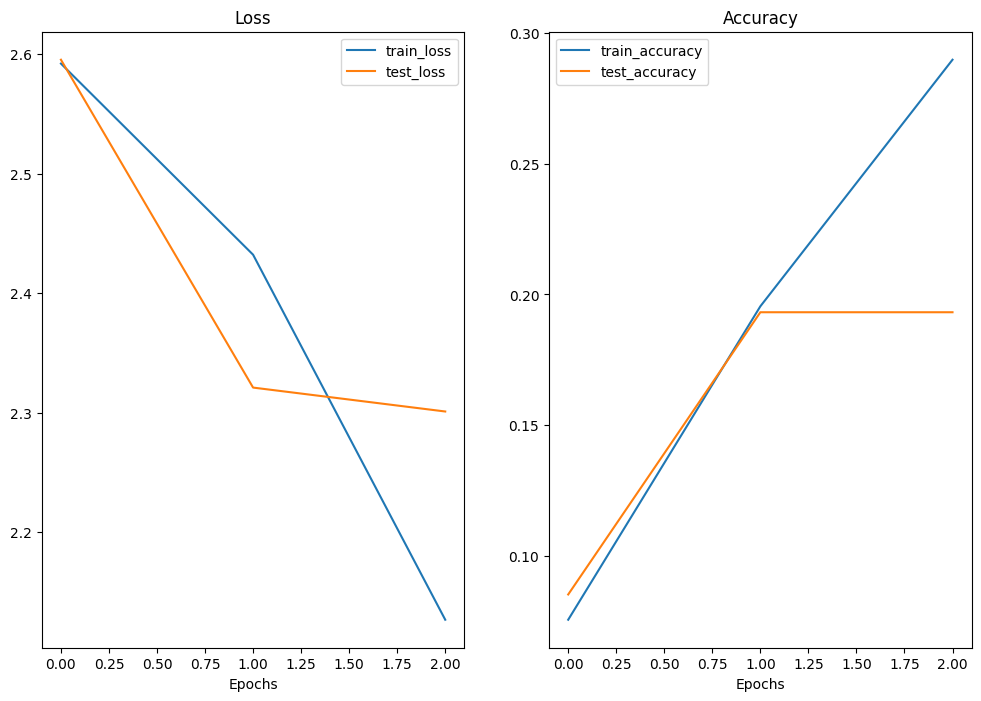

In [ ]:
plot_loss_curves(model_0_results)

## 8. What should a loss curve look like?

A loss curve is a helpful way to troubleshoot a model.

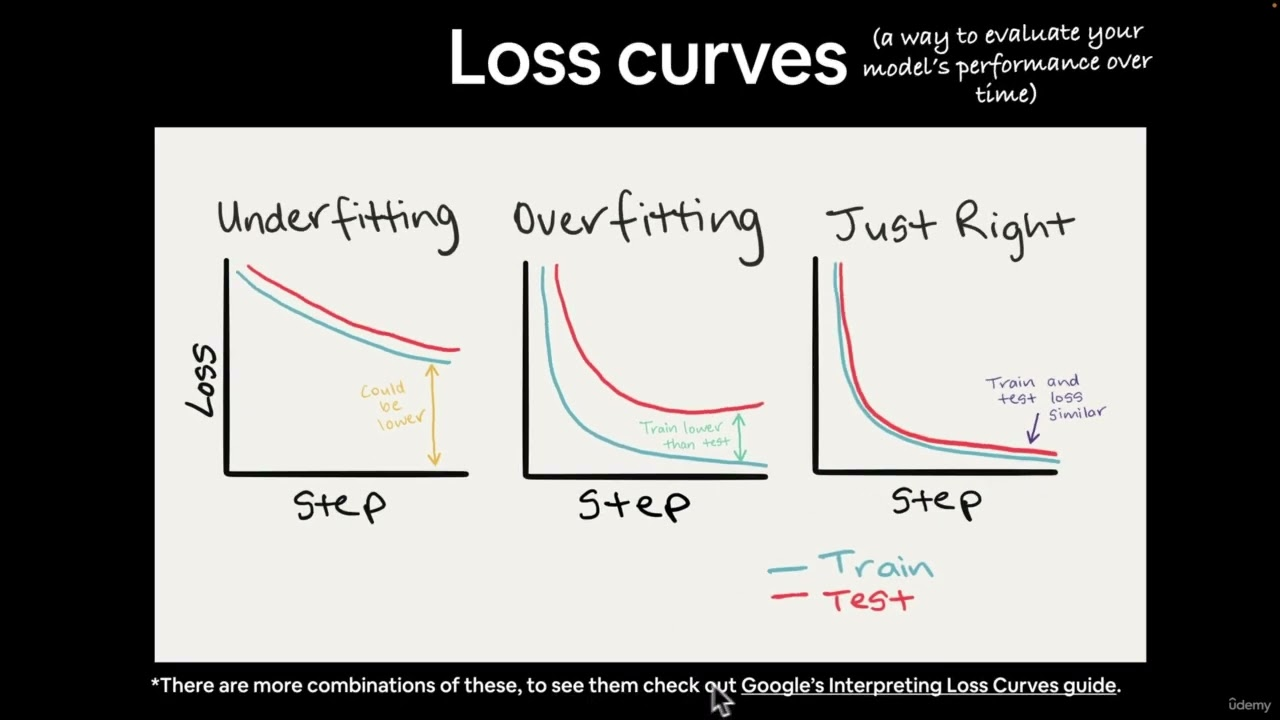

Underfitting (High Bias)
- Increase model complexity: Use a more complex model (e.g., polynomial regression instead of linear), or add more hidden layers or neurons to a neural network.

- Add more features: Include additional relevant features in your data through feature engineering to help the model learn more intricate relationships.

- Increase training time: Train the model for more epochs, giving it more time to learn the patterns.

- Reduce regularization: If you're using regularization, it might be too strong. Decrease the penalty to allow the model to fit the data better.

Overfitting (High Variance)
- Increase training data: Get more representative training data. If you can't, use data augmentation to create more data artificially.

- Simplify the model: Use a simpler model or reduce the complexity of your existing model, such as removing layers from a neural network or limiting the depth of a decision tree.

- Use regularization: Apply techniques like L1 or L2 regularization to penalize complex models, or use dropout in neural networks to randomly "drop" neurons during training.

- Early stopping: Monitor the model's performance on a separate validation set and stop training as soon as performance starts to decrease.

## 9. TinyVGG with Data Augmentation

Now let's try another model; Same model with different with different data

In [ ]:
from torchvision import transforms

train_transform_trivial = transforms.Compose([
    transforms.Resize(size=(64, 64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31), # how intense
    transforms.ToTensor() # use ToTensor() last to get everything between 0 & 1
])

# Don't need to perform augmentation on the test data
test_transforms = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

## 9.2 Create train and test `Dataset` and `Dataloader` with data augmentation

In [ ]:
from torchvision import datasets
train_data_augmented = datasets.ImageFolder(root= train_dir, transform= train_transform_trivial)
test_data_simple = datasets.ImageFolder(root= test_dir, transform= test_transforms)

In [ ]:
import os
from torch.utils.data import DataLoader
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

train_dataloader_augmented = DataLoader(dataset= train_data_augmented, batch_size = BATCH_SIZE, shuffle = True, num_workers = NUM_WORKERS)
test_dataloader = DataLoader(dataset= test_data_simple, batch_size = BATCH_SIZE, shuffle = False, num_workers = NUM_WORKERS)

## 9.3 Construct and train model 1

In [ ]:
# Create model and send to target device
model_1 = TinyVGG(input_shape= 3, hidden_units=10, output_shape=len(train_data_augmented.classes)).to(device)
model_1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=14, bias=True)
  )
)

Now that we have a model and dataloaders, let's create a loss function and an optimizer and call upon our `train()` function to train and evavluate our model.

In [ ]:
NUM_EPOCHS = 3
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model_1.parameters(), lr= 0.001)
from timeit import default_timer as timer
start_time  = timer()

model_1_results = train(model = model_1, train_dataloader=train_dataloader_augmented, test_dataloader = test_dataloader_simple, optimizer = optimizer, loss_fn= loss_fn, epochs = NUM_EPOCHS, device = device)

end_time = timer()
print(f' Total training time for model_1 : {end_time - start_time:.3f} seconds')

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 2.5955 | train_acc: 0.0847 | test_loss: 2.5965 | test_acc: 0.0284
Epoch: 2 | train_loss: 2.5798 | train_acc: 0.0955 | test_loss: 2.5760 | test_acc: 0.1307
Epoch: 3 | train_loss: 2.5203 | train_acc: 0.1335 | test_loss: 2.4964 | test_acc: 0.1165
 Total training time for model_1 : 45.430 seconds


## 9.4 Plot the loss curve for model_1

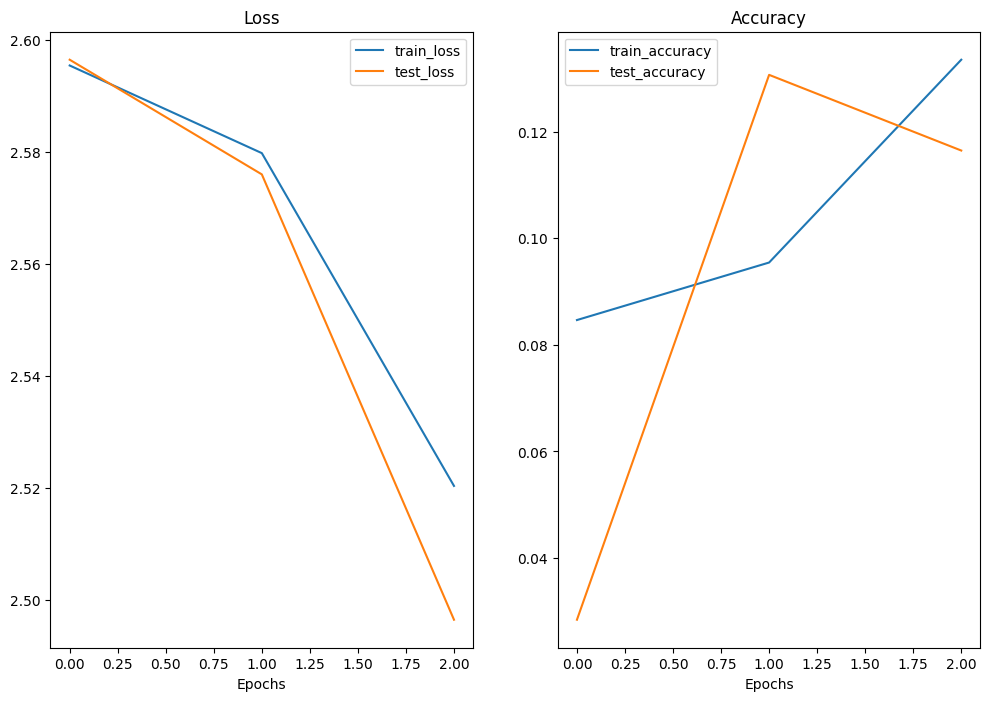

In [ ]:
plot_loss_curves(model_1_results)

## 10. Compare model results

In [ ]:
import pandas as pd
model_0_df = pd.DataFrame(model_0_results)
model_1_df = pd.DataFrame(model_1_results)
model_0_df

,train_loss,train_acc,test_loss,test_acc
0,2.592043,0.075568,2.595274,0.085227
1,2.432164,0.195455,2.321009,0.193182
2,2.126818,0.289773,2.301006,0.193182


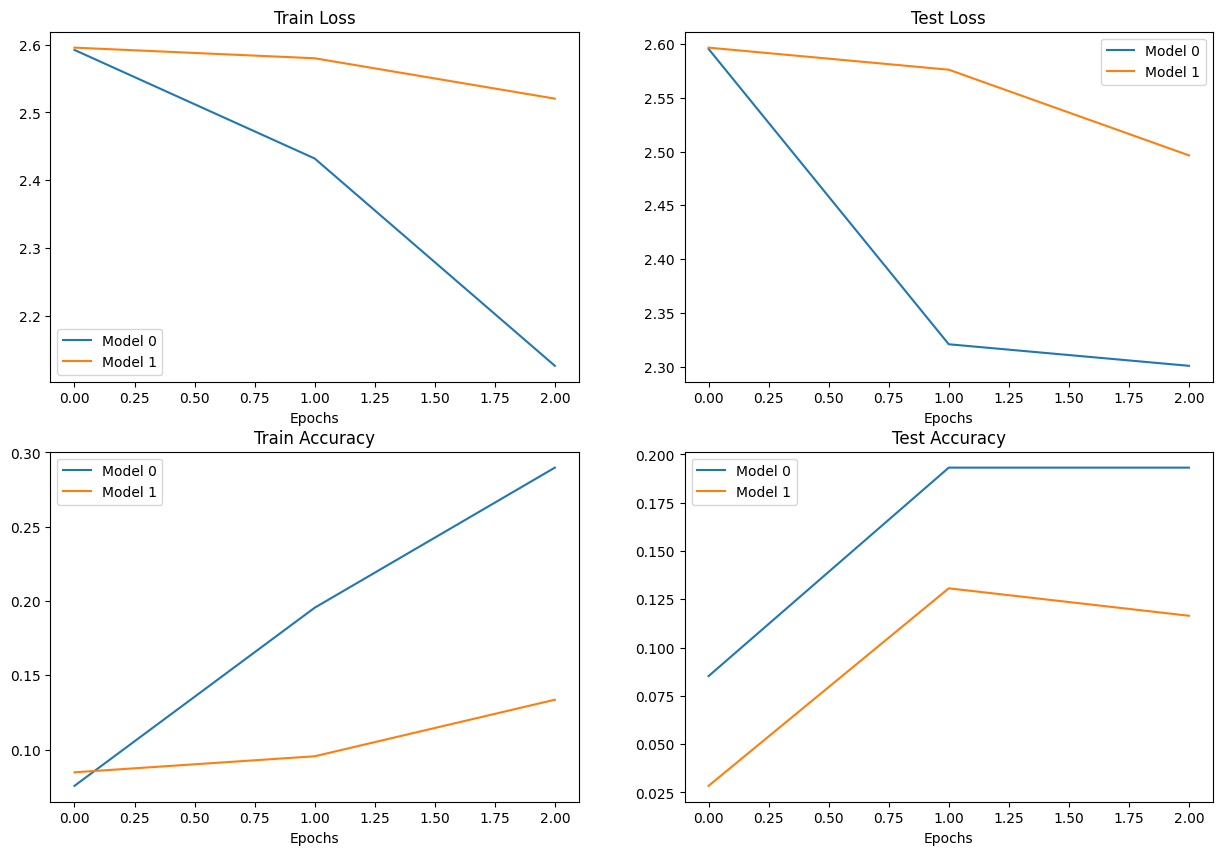

In [ ]:
# Setup a plot
plt.figure(figsize=(15, 10))

# Get number of epochs for each model
epochs_0 = range(len(model_0_df))
epochs_1 = range(len(model_1_df))

# Plot train loss
plt.subplot(2, 2, 1)
plt.plot(epochs_0, model_0_df["train_loss"], label="Model 0")
plt.plot(epochs_1, model_1_df["train_loss"], label="Model 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot test loss
plt.subplot(2, 2, 2)
plt.plot(epochs_0, model_0_df["test_loss"], label="Model 0")
plt.plot(epochs_1, model_1_df["test_loss"], label="Model 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot train accuracy
plt.subplot(2, 2, 3)
plt.plot(epochs_0, model_0_df["train_acc"], label="Model 0")
plt.plot(epochs_1, model_1_df["train_acc"], label="Model 1")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

# Plot test accuracy
plt.subplot(2, 2, 4)
plt.plot(epochs_0, model_0_df["test_acc"], label="Model 0")
plt.plot(epochs_1, model_1_df["test_acc"], label="Model 1")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend();

## 11. Making predictions with our model.

## 11.1 Loading in a custom image with pytorch
We have to make sure that the tensor shape is the same to aviod dtype and shape size errors
- Of shape 64x64x3
- On the right device


In [ ]:

from pathlib import Path # Import Path
custom_image_path = Path("/content/data_model/train/Hammer/1206_png_jpg.rf.671bbf66ec974280379a4027cde4918e.jpg")

In [ ]:
import torchvision
# Make sure the custom_image_path in the cell above points to a valid image file
custom_image_uint8 = torchvision.io.read_image(str(custom_image_path))
print(f'Custom image tensor: {custom_image_uint8}')
print(f'Custom image shape: {custom_image_uint8.shape} ')
print("")

Custom image tensor: tensor([[[254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         ...,
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254]],

        [[254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         ...,
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254]],

        [[254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         ...,
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254],
         [254, 254, 254,  ..., 254, 254, 254]]], dtype=torch.uint8)
Custom image shape: torch.Size([3, 640, 640]) 



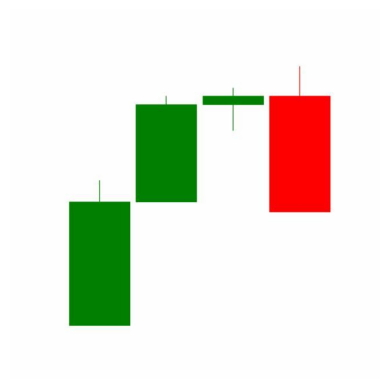

In [ ]:
plt.axis("off")
plt.imshow(custom_image_uint8.permute(1, 2, 0))

## 11.2 Making a prediction on a custom iamge with trained Pytorch model

In [ ]:
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32)
custom_image = custom_image / 255.0 # We divide by 255
custom_image

tensor([[[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         ...,
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961]],

        [[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         ...,
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961]],

        [[0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.9961],
         [0.9961, 0.9961, 0.9961,  ..., 0.9961, 0.9961, 0.

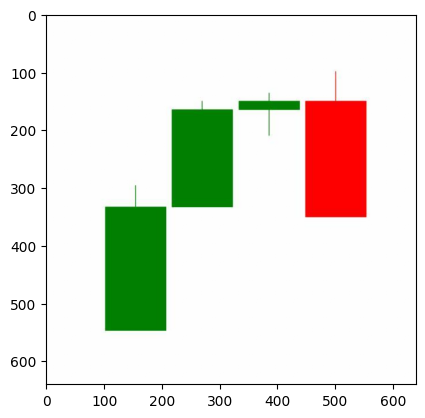

In [ ]:
plt.imshow(custom_image.permute(1, 2, 0))

In [ ]:
# Create transform pipline to resize image.
custom_image_transform = transforms.Compose([ transforms.Resize((64, 64))]) # Corrected the Resize call

print(f"Shape of image before transform: {custom_image.shape}") # Add print statement

custom_image_transformed = custom_image_transform(custom_image)

print(f" Original shape: {custom_image.shape}")
print(f" Transformed shape: {custom_image_transformed.shape}")

Shape of image before transform: torch.Size([3, 640, 640])
 Original shape: torch.Size([3, 640, 640])
 Transformed shape: torch.Size([3, 64, 64])


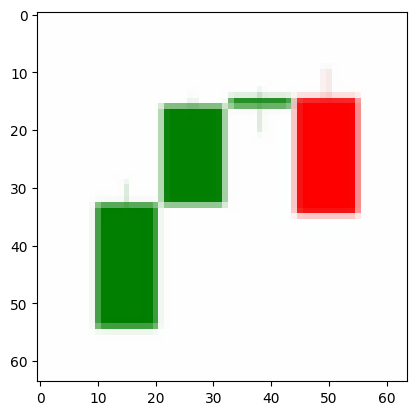

In [ ]:
plt.imshow(custom_image_transformed.permute(1, 2, 0))

In [ ]:
model_1.eval()
with torch.inference_mode():
  custom_image_pred= model_1(custom_image_transformed.unsqueeze(0).to(device))
custom_image_pred


tensor([[-0.2899, -1.2236,  0.6549, -0.8417, -0.5320,  0.4198,  0.2733, -0.2841,
         -1.7607, -1.3161,  0.1068, -0.6831, -0.4968, -1.6005]])

In [ ]:
class_names = train_data_augmented.classes
class_names

['Advance Block',
 'Dragonfly Doji',
 'Evening Star',
 'Gravestone Doji',
 'Hammer',
 'Hanging Man',
 'Hikkake Pattern',
 'Marubozu',
 'Morning Star',
 'Spinning Top',
 'Three Inside Up-Down',
 'Three Line Strike',
 'Three Outside Up-Down',
 'Upside-Downside Gap Three Methods']

Note that to make a prediction on a custom image, we had to:
- Load the iamge and turn it into a tensor
- Make sure that the same dtype as the model (torch.float32)
- Make sure the iamge was the same shape as the data the model was trained on (3, 64, 64) with a batch size... (1, 3, 64, 64)
- Make sure image was on the same device as our model

In [ ]:
# COnvert logits into prediction probabilities
custom_image_pred_probs = torch.softmax(custom_image_pred, dim=1)
custom_image_pred_probs

tensor([[0.0717, 0.0282, 0.1843, 0.0413, 0.0563, 0.1457, 0.1259, 0.0721, 0.0165,
         0.0257, 0.1066, 0.0484, 0.0583, 0.0193]])

In [ ]:
# Convert pred probs => prediction labels
custom_image_pred_label = torch.argmax(custom_image_pred_probs, dim=1).cpu()
custom_image_pred_label

tensor([2])

In [ ]:
class_names[custom_image_pred_label]

'Evening Star'

## 11.3 Building a function

In [ ]:
import matplotlib.pyplot as plt
import torch
import torchvision # Import torchvision

def pred_and_plot(model: torch.nn.Module, image_path: str, class_names: List[str] = None, transform = None, device = device):
  """ Makes predictions on a target image and plots the image prediction """
  # Load in the image
  target_image = torchvision.io.read_image(str(image_path)).type(torch.float32) # Use torchvision.io.read_image

  # Divide the image pixel values by 255 to have them 0=>1
  target_image = target_image / 255.0

  # Transform the image to fit the model needs
  if transform:
    target_image = transform(target_image)

  # Make sure the model is on the target device
  model.to(device)

  # Turn on eval mode
  model.eval()

  # Turn on inference mode
  with torch.inference_mode():
    # Add extra dimension
    target_image = target_image.unsqueeze(dim=0)

    # Make prediction
    target_image_pred = model(target_image.to(device))

    # Convert logits -> prediction probabilities
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # Plot the image and print probability prediction
    plt.imshow(target_image.squeeze().permute(1, 2, 0)) # make sure it's the right size for matplotlib
    if class_names:
        title = f"Pred: {class_names[target_image_pred_label.cpu()]} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    else:
        title = f"Pred: {target_image_pred_label} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    plt.title(title)
    plt.axis(False);

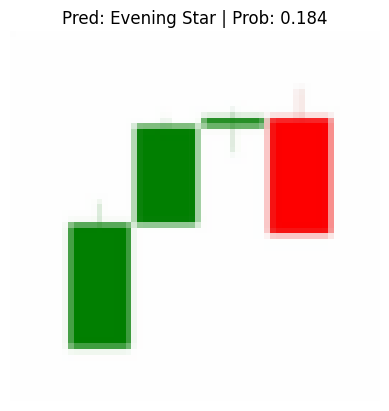

In [ ]:
# Pred on our custom image
pred_and_plot(model=model_1,
                    image_path=custom_image_path,
                    class_names=class_names,
                    transform=custom_image_transform,
                    device=device)

That is in fact the Evening star, a reversal trend....

Evening-Star-Candlestick-Definition-Structure-trading-advantages-Disadvantages-Banner.avif


# The end.
This was an end of the entire pytorch fundamentals series. Special thanks to Daniel Bourke who has this entire course free on youtube, which I strongly recommend. There are however more RL, LLM, ML and other deep learning projects, with a main focus of trading and investing capital.

#Happy Machine Learning!